## Cancelamento de clientes de telecomunicações: base de dados da IBM

### Sobre a base de dados

**Contexto:** Dados demográficos, serviços contratados, informações de conta e situação de cancelamento dos clientes de uma empresa fictícia de telecomunicações.

**Dados:** 7.043 clientes e 21 colunas na versão CSV. Esta versão não contém os campos geográficos, as pontuações de cancelamento nem os motivos de cancelamento da base anterior em Excel.

**Fonte:** [Kaggle: cancelamento de clientes de telecomunicações](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Variável alvo:** `Churn`, com os valores originais `Yes` (sim) e `No` (não). Os nomes originais das colunas são mantidos nas tabelas e nos gráficos. As categorias e os nomes das colunas permanecem no idioma original, inclusive nas visualizações.

### Roteiro da análise

1. Integridade dos dados: tipos, valores ausentes, duplicatas e cardinalidade das variáveis categóricas.
2. Distribuição das classes da variável alvo.
3. Distribuições numéricas, relações entre variáveis e distribuições categóricas.
4. Conclusões e considerações sobre o pré-processamento.
5. Treinamento de modelo com Regressão Logística (Scikit-Learn).
6. Treinamento de modelo baseado em Árvores de Decisão. Aplicar Validação Cruzada para garantir a robustez.
7. Treinamento de modelo baseado em  Rede  Neural  (utilizando  o  MLPClassifier  do  Scikit-Learn). Aplicar Validação Cruzada para garantir a robustez.
8. Comparação do desempenho dos modelos e escolha do modelo "campeão". 
9. Registro dos resultados dos experimentos. Tabela  comparativa  de  modelos  +  Modelo  final  escolhido  e 
salvo (.pkl ou .joblib).

### Importações

In [1]:
import json
import shutil
import kagglehub
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


from pathlib import Path
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 6)
RANDOM_STATE = 42

/home/thiagoney/GitHub/pos-tech-challenge-fase1/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_19295/3201472754.py:7: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


### 1. Integridade dos dados

O arquivo CSV é obtido do Kaggle por `kagglehub` na primeira execução e reutilizado localmente nas seguintes. Instale a dependência com `%pip install kagglehub` caso necessário.


In [ ]:
# Leitura de dados
project_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / "pyproject.toml").is_file()
     and (directory / "notebooks").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Run this notebook from the project root or notebooks directory.")

DATA_PATH = project_root / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

if not DATA_PATH.exists():
    dataset_path = kagglehub.dataset_download("blastchar/telco-customer-churn")
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(Path(dataset_path) / DATA_PATH.name, DATA_PATH)

df = pd.read_csv(DATA_PATH)

# Converter somente o tipo numérico
raw_total_charges = df["TotalCharges"].copy()
df["TotalCharges"] = pd.to_numeric(raw_total_charges, errors="coerce")
invalid_total_charges = (
    raw_total_charges.notna()
    & raw_total_charges.astype(str).str.strip().ne("")
    & df["TotalCharges"].isna()
)

print(f"Base de dados: {df.shape[0]} clientes e {df.shape[1]} colunas")
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Identificadores duplicados: {df['customerID'].duplicated().sum()}")
print(f"TotalCharges inválidos (não vazios): {invalid_total_charges.sum()}")

schema_summary = pd.DataFrame(
    {"DataType": df.dtypes.astype(str), "NonNullCount": df.notna().sum()}
)
display(schema_summary)

missing_summary = pd.DataFrame(
    {"MissingCount": df.isna().sum(), "MissingPercent": df.isna().mean().mul(100)}
)
display(missing_summary[missing_summary["MissingCount"] > 0])

Base de dados: 7043 clientes e 21 colunas
Linhas duplicadas: 0
Identificadores duplicados: 0
TotalCharges inválidos (não vazios): 0


,DataType,NonNullCount
customerID,object,7043
gender,object,7043
SeniorCitizen,int64,7043
Partner,object,7043
Dependents,object,7043
tenure,int64,7043
PhoneService,object,7043
MultipleLines,object,7043
InternetService,object,7043
OnlineSecurity,object,7043


,MissingCount,MissingPercent
TotalCharges,11,0.16


### Cardinalidade das variáveis categóricas

In [3]:
# A variável de pessoa idosa é uma categoria binária, embora armazenada como inteiro.
categorical_columns = [
    column
    for column in df.select_dtypes(include=["object", "string", "category"]).columns
    if column not in {"customerID", "Churn"}
]
categorical_columns.append("SeniorCitizen")

unique_counts = df[categorical_columns].nunique(dropna=False)
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(unique_counts.index, unique_counts.values)
ax.bar_label(bars, padding=3)
ax.set_title("Quantidade de valores únicos por variável categórica")
ax.set_xlabel("Valores únicos")
ax.set_xlim(0, unique_counts.max() + 1)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

for column in categorical_columns:
    values = sorted(df[column].dropna().unique().tolist(), key=str)
    print(f"{column}: {values}")

<Figure size 1000x700 with 1 Axes>

gender: ['Female', 'Male']
Partner: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No', 'No phone service', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'No internet service', 'Yes']
OnlineBackup: ['No', 'No internet service', 'Yes']
DeviceProtection: ['No', 'No internet service', 'Yes']
TechSupport: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
StreamingMovies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['No', 'Yes']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
SeniorCitizen: [0, 1]


### Interpretação das categorias

Os valores originais `No internet service` (sem serviço de internet) e `No phone service` (sem serviço telefônico) indicam clientes que não possuem o serviço correspondente. São categorias válidas, e não observações ausentes. A variável `SeniorCitizen` utiliza `0` e `1`.

### 2. Distribuição da variável alvo

In [ ]:
churn_values = (
    df.groupby("Churn", dropna=False).size().rename("CustomerCount").reset_index()
)
churn_values["Percent"] = churn_values["CustomerCount"].div(len(df)).mul(100).round(2)
display(churn_values)

# fig, ax = plt.subplots()
# bars = ax.bar(churn_values["Churn"], churn_values["CustomerCount"])
# ax.bar_label(
#     bars,
#     labels=[
#         f"{count:,} ({percent:.2f}%)"
#         for count, percent in zip(
#             churn_values["CustomerCount"], churn_values["Percent"]
#         )
#     ],
#     padding=3,
# )
# ax.set_ylim(0, churn_values["CustomerCount"].max() * 1.15)
# ax.set_xlabel("Churn")
# ax.set_ylabel("Clientes")
# ax.set_title("Distribuição das classes de cancelamento")
# plt.tight_layout()

,Churn,CustomerCount,Percent
0,No,5174,73.46
1,Yes,1869,26.54


### 3. Distribuições das variáveis e relações numéricas

,OutlierCount
tenure,0
MonthlyCharges,0
TotalCharges,0


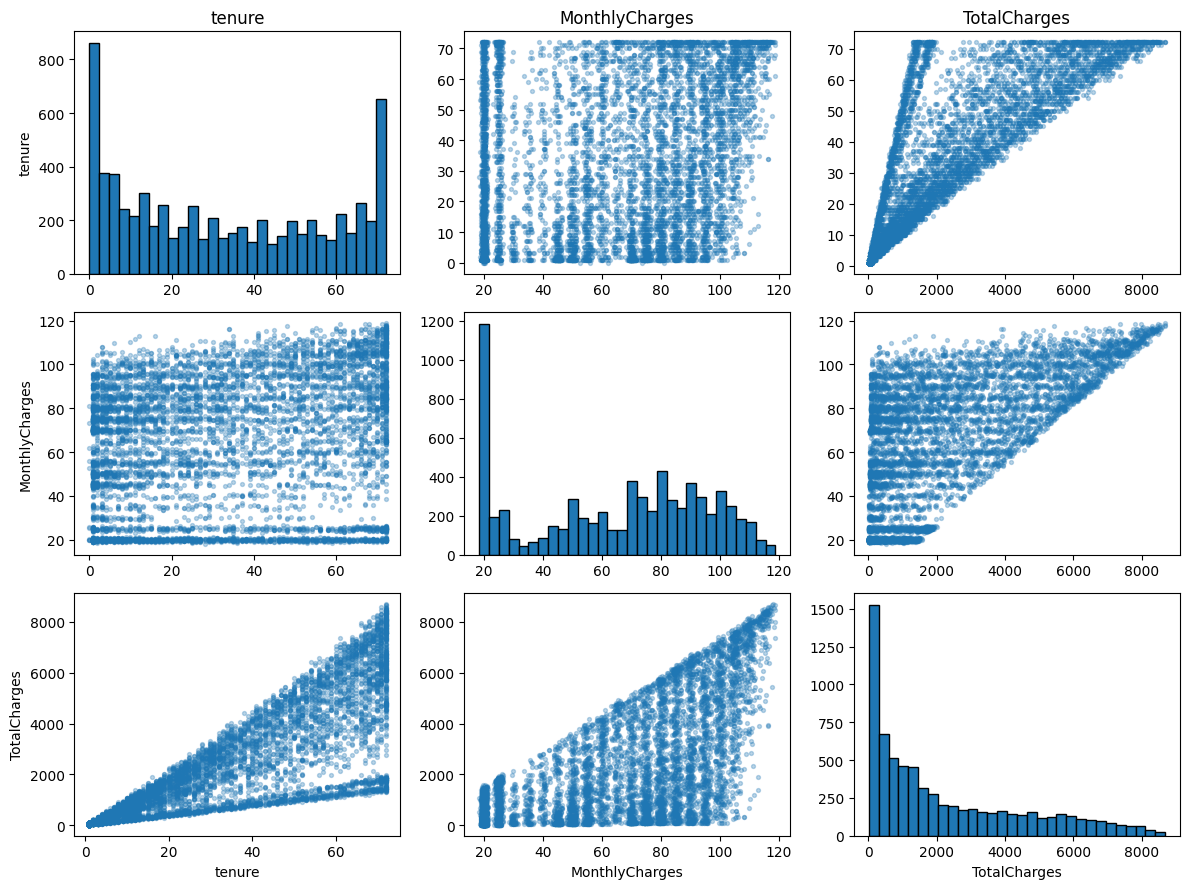

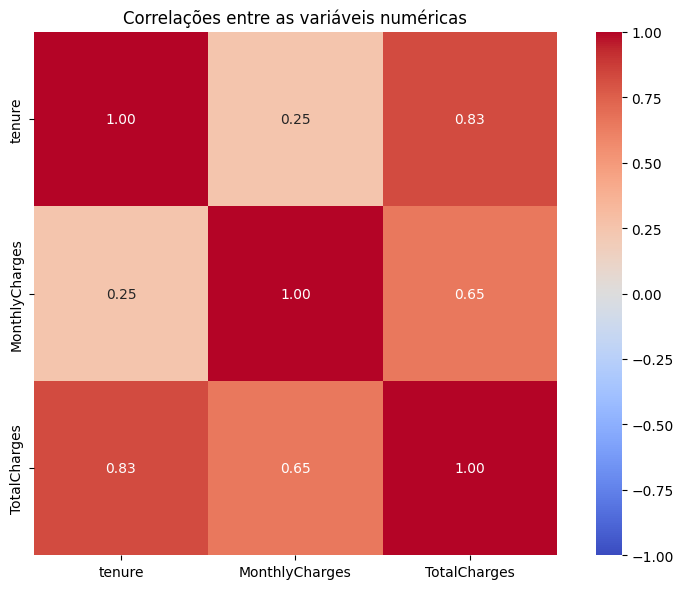

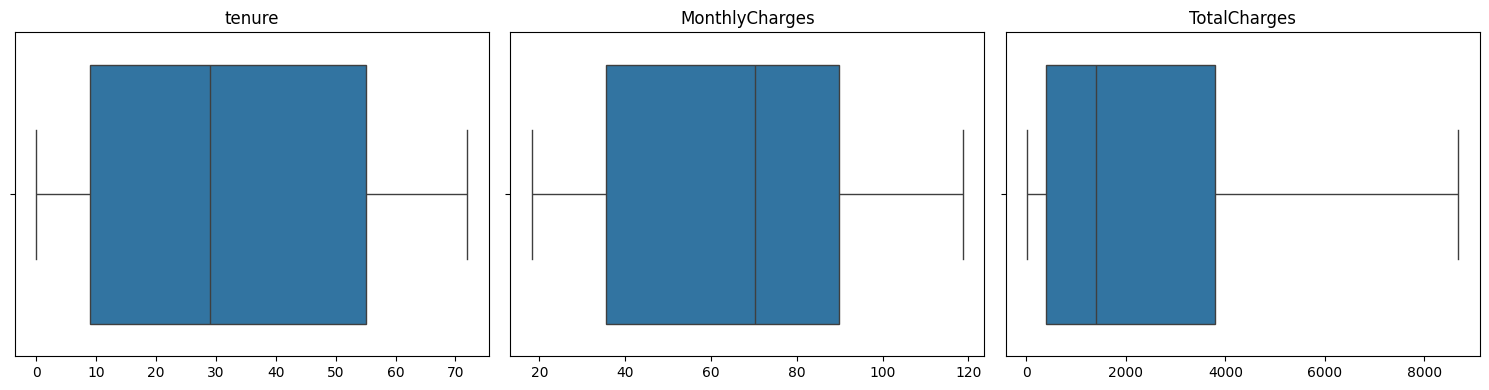

In [12]:
# Excluir a categoria demográfica binária da análise numérica contínua.
numeric_columns = [
    column
    for column in df.select_dtypes(include=np.number).columns
    if column != "SeniorCitizen"
]

n_columns = len(numeric_columns)
fig, axes = plt.subplots(
    n_columns, n_columns, figsize=(4 * n_columns, 3 * n_columns), squeeze=False
)
for row, y_column in enumerate(numeric_columns):
    for col, x_column in enumerate(numeric_columns):
        ax = axes[row, col]
        if row == col:
            ax.hist(df[x_column].dropna(), bins=30, edgecolor="black")
        else:
            pair = df[[x_column, y_column]].dropna()
            ax.scatter(pair[x_column], pair[y_column], alpha=0.3, s=8)
        if row == 0:
            ax.set_title(x_column)
        if col == 0:
            ax.set_ylabel(y_column)
        if row == n_columns - 1:
            ax.set_xlabel(x_column)
plt.tight_layout()

correlation_matrix = df[numeric_columns].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
)
plt.title("Correlações entre as variáveis numéricas")
plt.tight_layout()

fig, axes = plt.subplots(1, n_columns, figsize=(5 * n_columns, 4), squeeze=False)
for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(x=df[column], ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")
plt.tight_layout()

# Contar observações fora dos limites de 1,5 vez a amplitude interquartil.
quartiles = df[numeric_columns].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
outlier_counts = (
    df[numeric_columns].lt(quartiles.loc[0.25] - 1.5 * iqr)
    | df[numeric_columns].gt(quartiles.loc[0.75] + 1.5 * iqr)
).sum()
display(outlier_counts.rename("OutlierCount").to_frame())

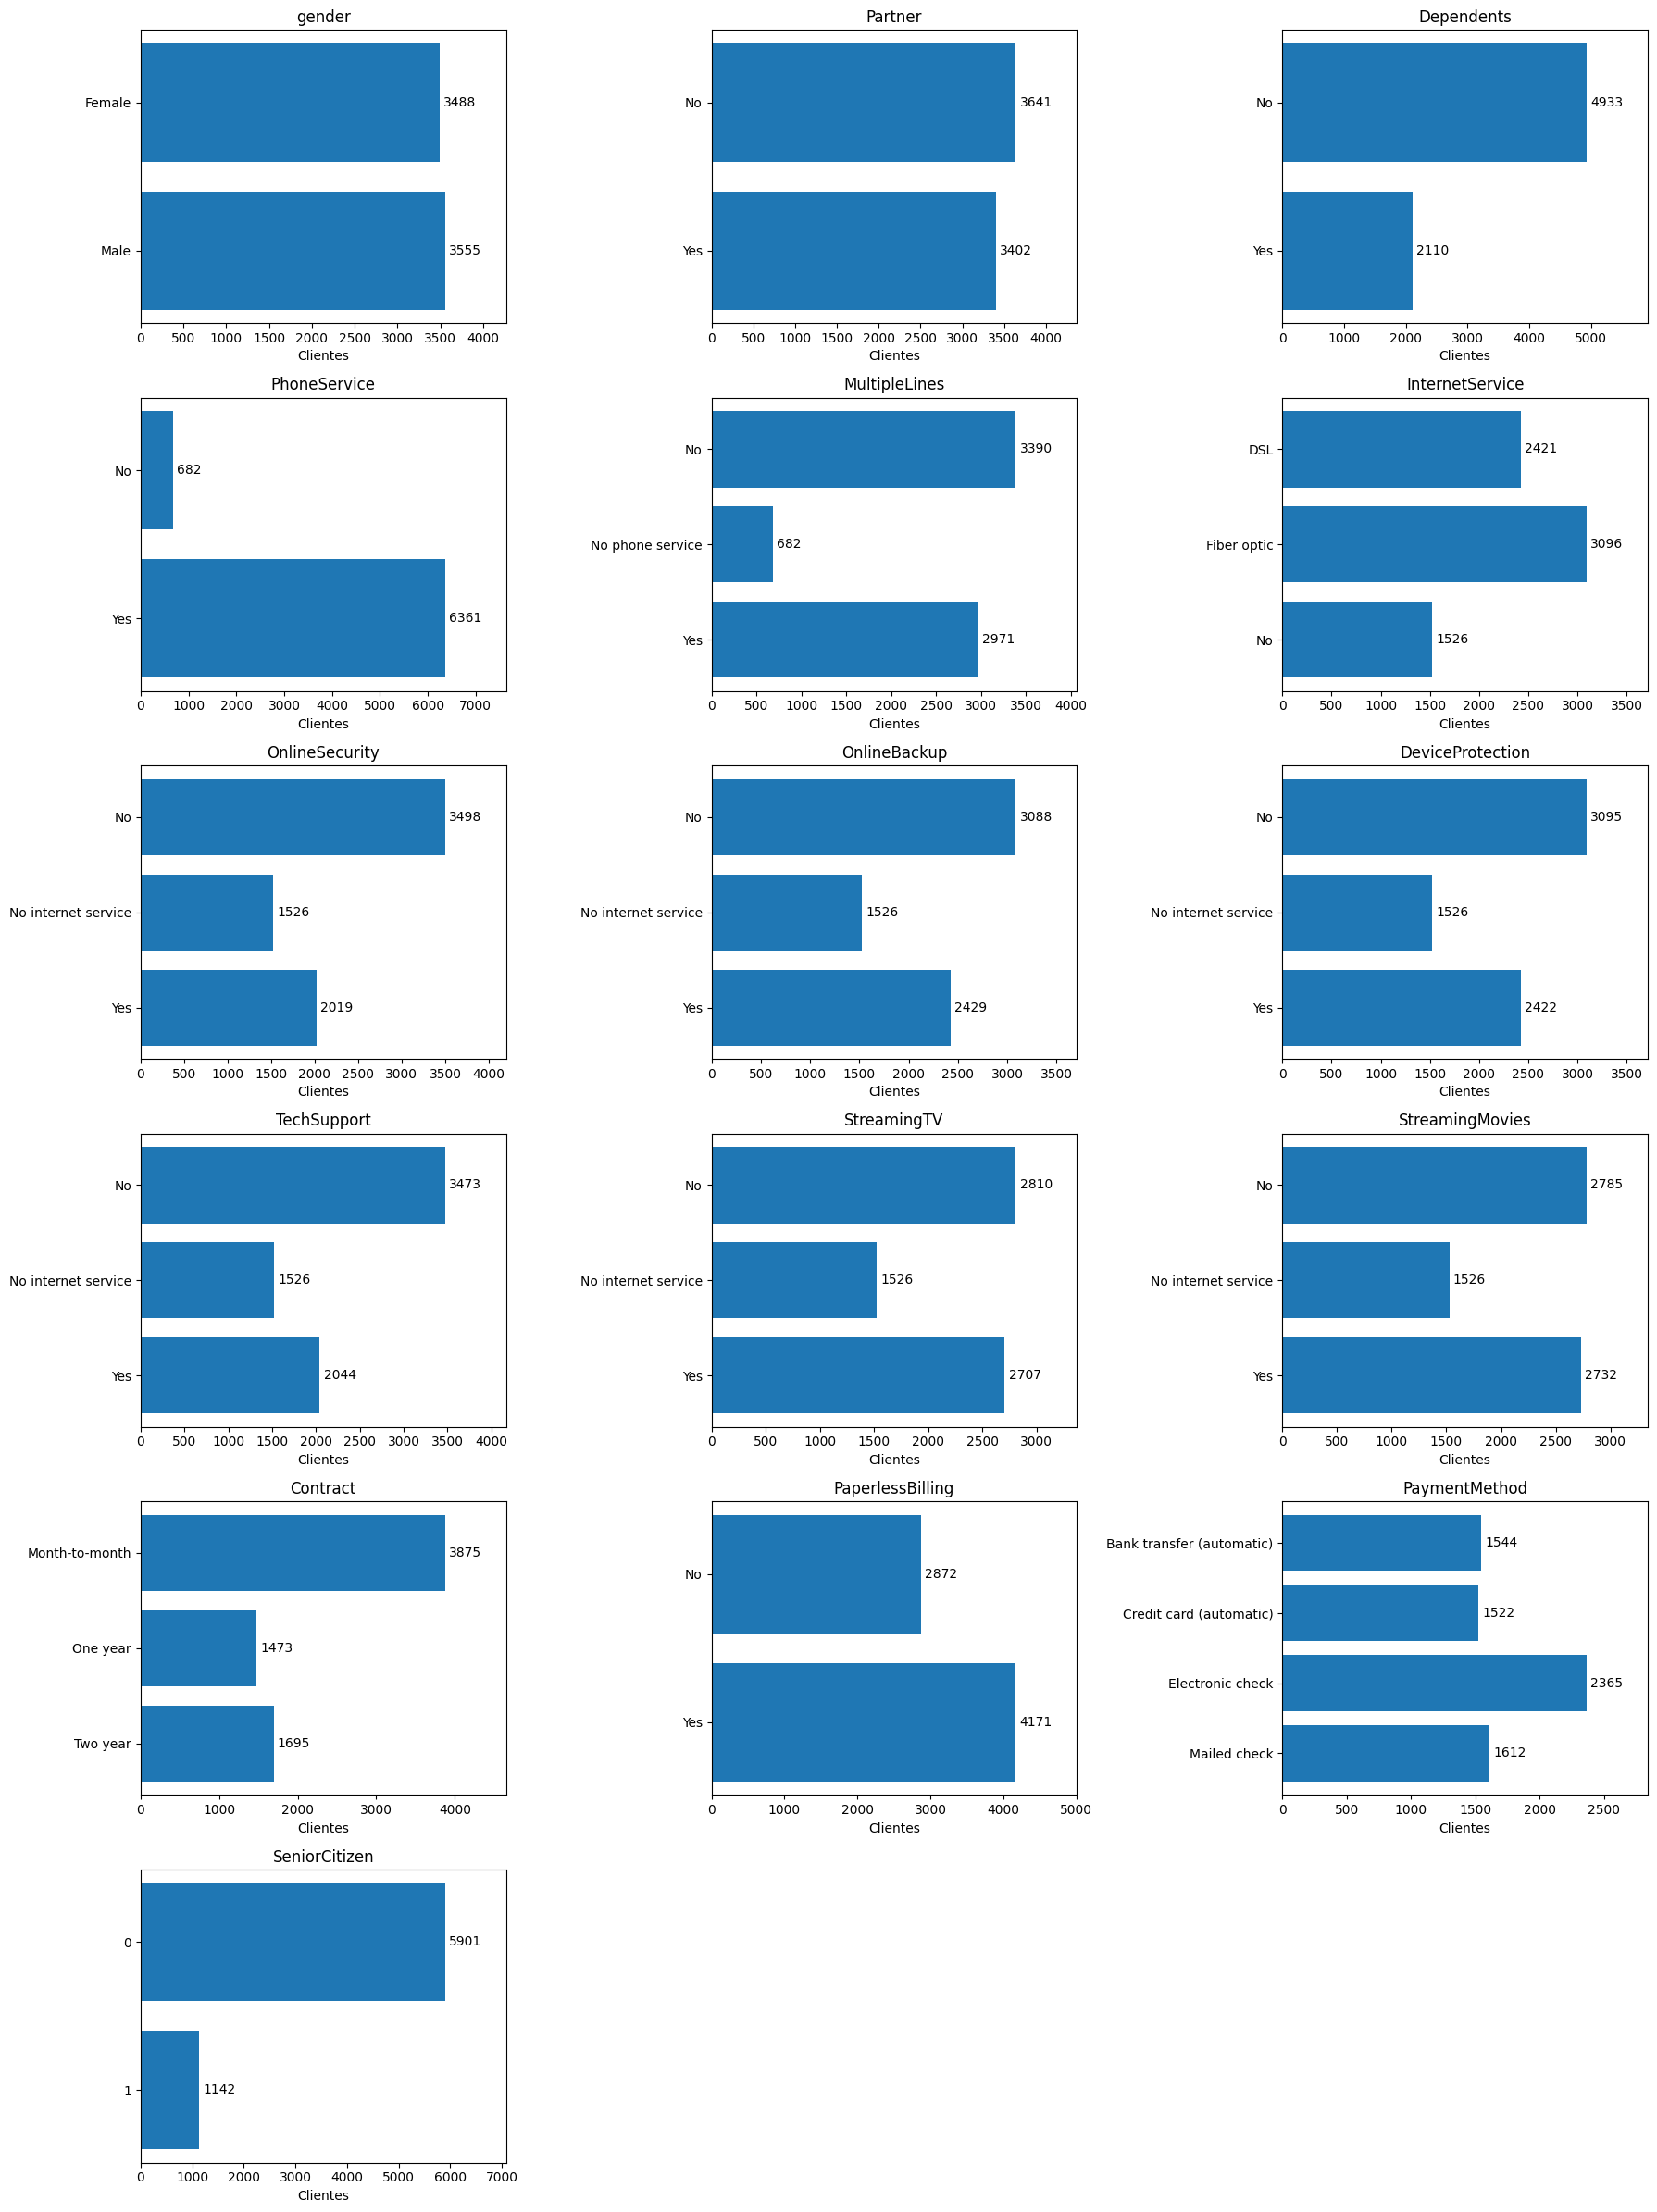

In [6]:
n_plot_columns = 3
n_plot_rows = (len(categorical_columns) + n_plot_columns - 1) // n_plot_columns
fig, axes = plt.subplots(
    n_plot_rows,
    n_plot_columns,
    figsize=(18, 4 * n_plot_rows),
    squeeze=False,
)
for ax, column in zip(axes.flat, categorical_columns):
    counts = df[column].value_counts(dropna=False).sort_index()
    bars = ax.barh(
        [str(value) for value in counts.index],
        counts.values,
    )
    ax.bar_label(bars, padding=3)
    ax.set_title(column)
    ax.set_xlabel("Clientes")
    ax.set_xlim(0, counts.max() * 1.2)
    ax.invert_yaxis()
for ax in list(axes.flat)[len(categorical_columns) :]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### Conclusões

- O CSV contém 7.043 linhas e 21 colunas, sem linhas ou identificadores de clientes duplicados. Excluir `customerID` das entradas do modelo, pois é um identificador.
- `TotalCharges` contém 11 valores em branco (0,16%); todos ocorrem em clientes com `tenure = 0`. Mantê-los ausentes durante a análise exploratória e definir uma política explícita de preenchimento antes da modelagem.
- A variável `Churn` é desbalanceada: 5.174 clientes (73,46%) apresentam `No` (não) e 1.869 (26,54%) apresentam `Yes` (sim). Usar divisões estratificadas e avaliar o desempenho nas duas classes.
- Tratar `SeniorCitizen` como variável categórica, apesar de seu armazenamento como número inteiro. Codificar as demais variáveis preditoras categóricas antes da modelagem.
- `TotalCharges` apresenta correlação com `tenure` (0,83) e `MonthlyCharges` (0,65).

### 4. Pré-processamento e separação dos dados

A imputação, a codificação e a padronização são ajustadas exclusivamente nos dados de treinamento de cada partição, evitando vazamento de dados.

In [ ]:
feature_columns = [column for column in df.columns if column not in {"customerID", "Churn"}]
X = df[feature_columns].copy()
y = df["Churn"].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("A variável Churn contém categorias inesperadas.")
y = y.astype(int)
X["SeniorCitizen"] = X["SeniorCitizen"].astype(str)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Treinamento: {len(X_train)} | Teste: {len(X_test)}")
print(f"Proporção de Churn=Yes no treino: {y_train.mean():.2%}")

Treinamento: 5634 | Teste: 1409
Proporção de Churn=Yes no treino: 26.54%


### 5–7. Treinamento e validação cruzada

Três classificadores são avaliados com as mesmas cinco partições estratificadas. A seleção utiliza ROC AUC médio; F1, recall e acurácia balanceada complementam a avaliação.

In [8]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "DecisionTree": DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=20, random_state=RANDOM_STATE
    ),
    "MLPClassifier": MLPClassifier(
        hidden_layer_sizes=(64, 32), alpha=0.01, max_iter=500,
        early_stopping=True, n_iter_no_change=20, random_state=RANDOM_STATE,
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "balanced_accuracy": "balanced_accuracy",
}

results = []
for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    cv_scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, error_score="raise",
    )
    results.append(
        {
            "Model": model_name,
            **{
                f"{metric}_mean": cv_scores[f"test_{metric}"].mean()
                for metric in scoring
            },
            **{
                f"{metric}_std": cv_scores[f"test_{metric}"].std()
                for metric in scoring
            },
        }
    )

comparison_df = pd.DataFrame(results).sort_values(
    ["roc_auc_mean", "f1_mean"], ascending=False
).reset_index(drop=True)
display(comparison_df.round(4))

,Model,roc_auc_mean,f1_mean,recall_mean,balanced_accuracy_mean,roc_auc_std,f1_std,recall_std,balanced_accuracy_std
0,LogisticRegression,0.85,0.59,0.54,0.72,0.01,0.03,0.04,0.02
1,MLPClassifier,0.84,0.59,0.54,0.72,0.01,0.03,0.04,0.02
2,DecisionTree,0.83,0.57,0.51,0.70,0.01,0.03,0.05,0.02


### 8. Seleção do modelo e avaliação final

O conjunto de teste é utilizado somente após a escolha do modelo por validação cruzada.

Modelo selecionado: LogisticRegression
ROC AUC no teste: 0.8419
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



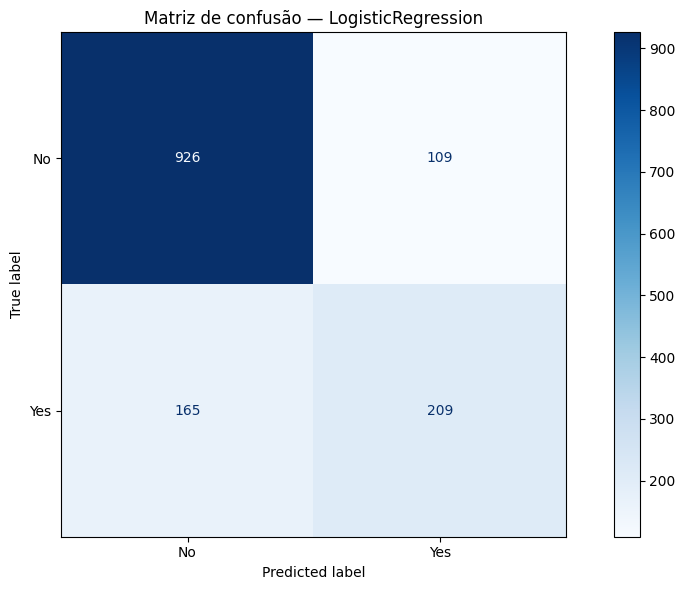

In [9]:
best_model_name = comparison_df.loc[0, "Model"]
best_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("model", models[best_model_name])]
)
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)
y_score = best_pipeline.predict_proba(X_test)[:, 1]
test_roc_auc = roc_auc_score(y_test, y_score)

print(f"Modelo selecionado: {best_model_name}")
print(f"ROC AUC no teste: {test_roc_auc:.4f}")
print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No", "Yes"], cmap="Blues"
)
plt.title(f"Matriz de confusão — {best_model_name}")
plt.tight_layout()
plt.show()

### 9. Registro dos experimentos e persistência

O artefato inclui o pré-processamento e o classificador. A métrica de teste é registrada separadamente da validação cruzada.

In [13]:
output_dir = project_root / "models"
output_dir.mkdir(parents=True, exist_ok=True)

model_path = output_dir / "telco_churn_best_model.joblib"
comparison_path = output_dir / "telco_churn_model_comparison.csv"
metadata_path = output_dir / "telco_churn_experiment.json"

joblib.dump(best_pipeline, model_path)
comparison_df.to_csv(comparison_path, index=False)

experiment_metadata = {
    "dataset": DATA_PATH.name,
    "target": "Churn",
    "positive_class": "Yes",
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "cv_folds": cv.n_splits,
    "selection_metric": "roc_auc_mean",
    "best_model": best_model_name,
    "cv_roc_auc_mean": float(comparison_df.loc[0, "roc_auc_mean"]),
    "test_roc_auc": float(test_roc_auc),
    "feature_columns": feature_columns,
}
metadata_path.write_text(
    json.dumps(experiment_metadata, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print(f"Modelo: {model_path}")
print(f"Comparação: {comparison_path}")
print(f"Metadados: {metadata_path}")

Modelo: /home/thiagoney/GitHub/pos-tech-challenge-fase1/models/telco_churn_best_model.joblib
Comparação: /home/thiagoney/GitHub/pos-tech-challenge-fase1/models/telco_churn_model_comparison.csv
Metadados: /home/thiagoney/GitHub/pos-tech-challenge-fase1/models/telco_churn_experiment.json
